# Preprocessing the Mushroom Dataset for scikit-learn
**IS 362 – Assignment: Preprocessing Data for scikit-learn**

**Goal:** Prepare the UCI Mushroom dataset for Project 4, where we'll ask: *which attributes best predict whether a mushroom is poisonous or edible?*

**Columns selected**
- `class` – edible or poisonous (the target)
- `odor` – required by the assignment
- `gill_size` – my additional column (broad vs. narrow gills)

**Data dictionary:** https://archive.ics.uci.edu/ml/datasets/Mushroom (see `agaricus-lepiota.names`)

## 1. Load the raw data
The file has no header row, so I read it directly from the UCI repository and select only the columns I need by position. Per the data dictionary, column 0 is `class`, column 5 is `odor`, and column 8 is `gill-size`.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

raw = pd.read_csv(URL, header=None)
print("Full raw shape:", raw.shape)
raw.head()

Full raw shape: (8124, 23)


,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## 2. Create a DataFrame with a subset of columns and meaningful names

In [9]:
df = raw[[0, 5, 8]].copy()
df.columns = ["class", "odor", "gill_size"]
print(df.shape)
print("Missing values:\n", df.isna().sum())
df.head()

(8124, 3)
Missing values:
 class        0
odor         0
gill_size    0
dtype: int64


,class,odor,gill_size
0,p,p,n
1,e,a,b
2,e,l,b
3,p,p,n
4,e,n,b


## 3. Replace the letter codes with numeric values
Codes come from the data dictionary. I keep the mappings in dictionaries so they are documented and reusable (e.g. for labeling plots).

In [10]:
class_map = {"e": 0, "p": 1}  # 0 = edible, 1 = poisonous

odor_map = {
    "a": 0,  # almond
    "l": 1,  # anise
    "c": 2,  # creosote
    "y": 3,  # fishy
    "f": 4,  # foul
    "m": 5,  # musty
    "n": 6,  # none
    "p": 7,  # pungent
    "s": 8,  # spicy
}

gill_size_map = {"b": 0, "n": 1}  # 0 = broad, 1 = narrow

# Keep a labeled copy for readable plots/tables
labels = df.copy()
labels["class"] = labels["class"].map({"e": "edible", "p": "poisonous"})
labels["odor"] = labels["odor"].map({"a": "almond", "l": "anise", "c": "creosote", "y": "fishy",
                                     "f": "foul", "m": "musty", "n": "none", "p": "pungent", "s": "spicy"})
labels["gill_size"] = labels["gill_size"].map({"b": "broad", "n": "narrow"})

# Numeric version for scikit-learn
df["class"] = df["class"].map(class_map)
df["odor"] = df["odor"].map(odor_map)
df["gill_size"] = df["gill_size"].map(gill_size_map)

print("Any unmapped (NaN) values?", df.isna().any().any())
print(df.dtypes)
df.head()

Any unmapped (NaN) values? False
class        int64
odor         int64
gill_size    int64
dtype: object


,class,odor,gill_size
0,1,7,1
1,0,0,0
2,0,1,0
3,1,7,1
4,0,6,0


## 4. Exploratory data analysis
### 4a. Distribution of each selected column

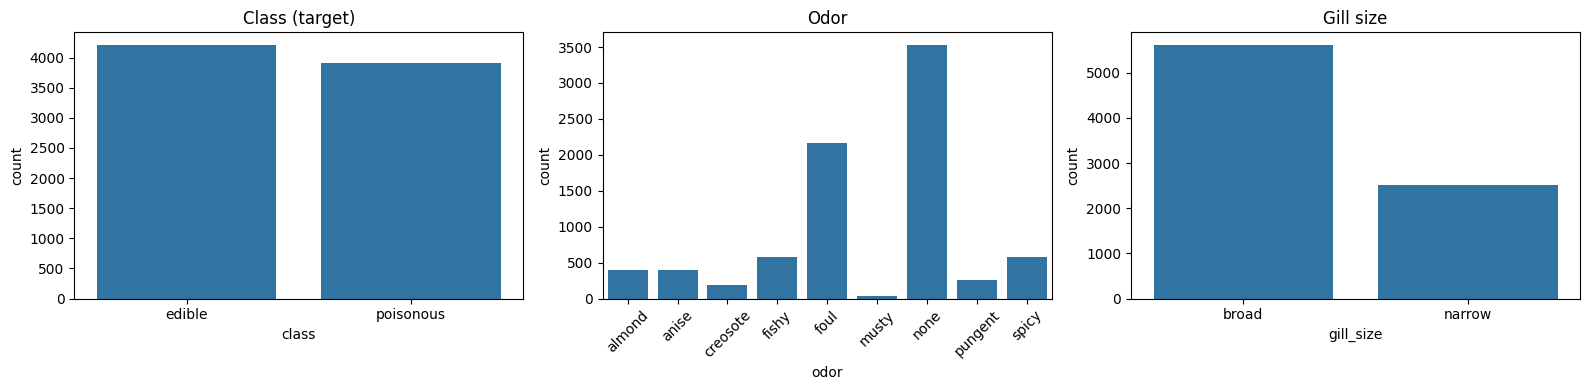

class
edible       0.517971
poisonous    0.482029
Name: proportion, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

order_class = ["edible", "poisonous"]
sns.countplot(data=labels, x="class", order=order_class, ax=axes[0])
axes[0].set_title("Class (target)")

order_odor = ["almond", "anise", "creosote", "fishy", "foul", "musty", "none", "pungent", "spicy"]
sns.countplot(data=labels, x="odor", order=order_odor, ax=axes[1])
axes[1].set_title("Odor")
axes[1].tick_params(axis="x", rotation=45)

sns.countplot(data=labels, x="gill_size", order=["broad", "narrow"], ax=axes[2])
axes[2].set_title("Gill size")

plt.tight_layout()
plt.show()

print(df["class"].value_counts(normalize=True).rename({0: "edible", 1: "poisonous"}))

### 4b. Scatterplots: class vs. odor and class vs. gill size
Because all three variables are categorical, plain scatterplots stack every point on top of each other. I add a small random jitter so the density at each combination is visible.

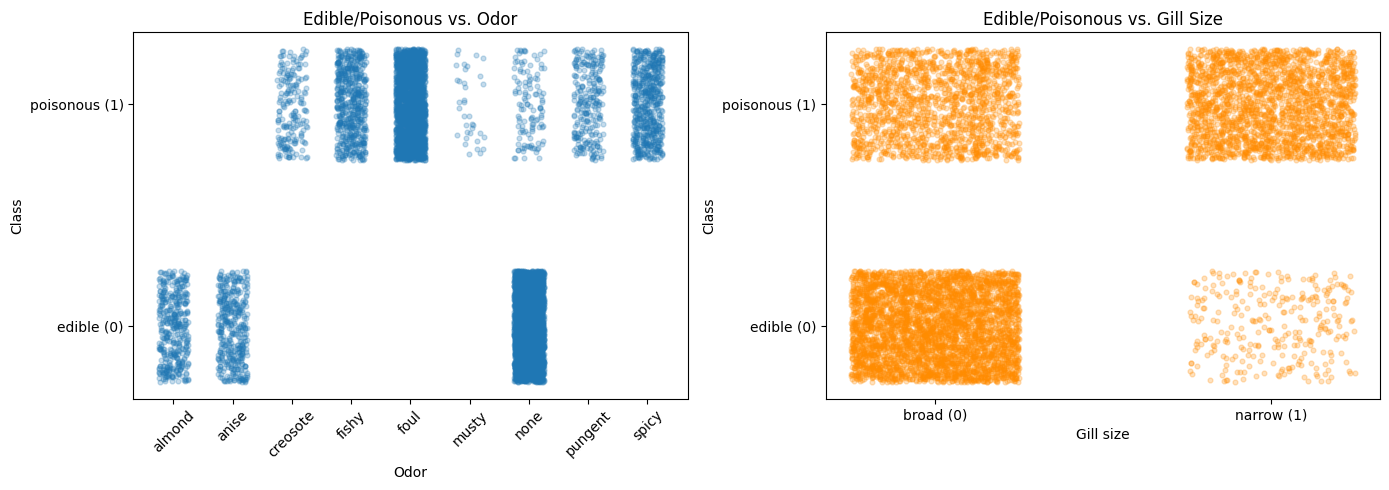

In [12]:
rng = np.random.default_rng(362)
jit = lambda n: rng.uniform(-0.25, 0.25, n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class vs odor
axes[0].scatter(df["odor"] + jit(len(df)), df["class"] + jit(len(df)), alpha=0.25, s=12)
axes[0].set_xticks(range(9)); axes[0].set_xticklabels(order_odor, rotation=45)
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["edible (0)", "poisonous (1)"])
axes[0].set_title("Edible/Poisonous vs. Odor")
axes[0].set_xlabel("Odor"); axes[0].set_ylabel("Class")

# Class vs gill size
axes[1].scatter(df["gill_size"] + jit(len(df)), df["class"] + jit(len(df)), alpha=0.25, s=12, color="darkorange")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["broad (0)", "narrow (1)"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["edible (0)", "poisonous (1)"])
axes[1].set_title("Edible/Poisonous vs. Gill Size")
axes[1].set_xlabel("Gill size"); axes[1].set_ylabel("Class")

plt.tight_layout()
plt.show()

### 4c. Supporting counts
Cross-tabulations make the scatterplot patterns exact.

Odor vs class (counts)


class,edible,poisonous
odor,,
almond,400,0
anise,400,0
creosote,0,192
fishy,0,576
foul,0,2160
musty,0,36
none,3408,120
pungent,0,256
spicy,0,576



Gill size vs class (counts)


class,edible,poisonous
gill_size,,
broad,3920,1692
narrow,288,2224


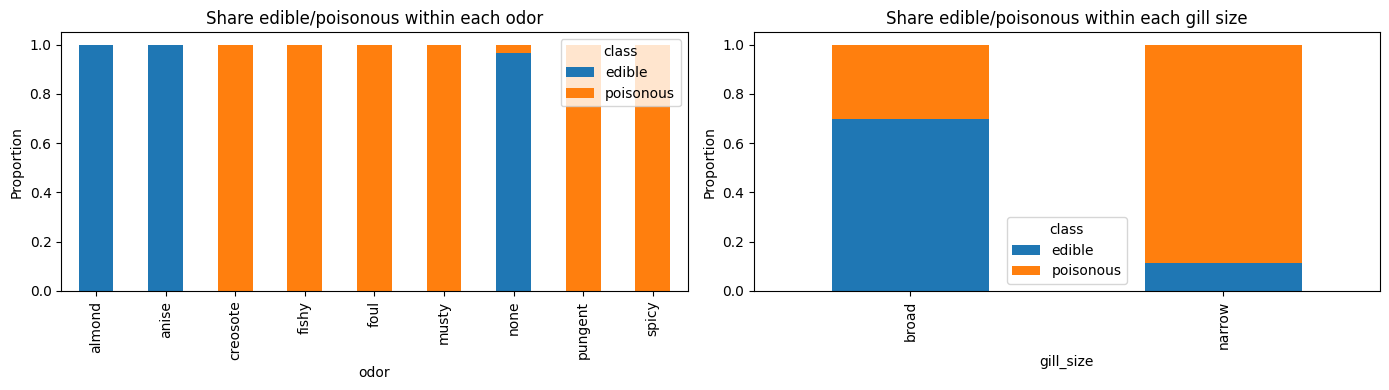

In [13]:
print("Odor vs class (counts)")
display(pd.crosstab(labels["odor"], labels["class"]))
print("\nGill size vs class (counts)")
display(pd.crosstab(labels["gill_size"], labels["class"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(labels["odor"], labels["class"], normalize="index").loc[order_odor].plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Share edible/poisonous within each odor"); axes[0].set_ylabel("Proportion")
pd.crosstab(labels["gill_size"], labels["class"], normalize="index").plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Share edible/poisonous within each gill size"); axes[1].set_ylabel("Proportion")
plt.tight_layout(); plt.show()

## 5. Preliminary conclusions

**Odor looks like a very strong predictor.** Most odor categories are essentially "pure": almond and anise mushrooms are all edible, while foul, fishy, spicy, pungent, creosote, and musty odors are all poisonous. Only the "none" category is mixed, but it is still mostly edible. A classifier using odor alone should therefore be highly accurate, with its errors concentrated among mushrooms that have no odor.

**Gill size looks moderately useful.** Broad-gilled mushrooms are mostly edible and narrow-gilled mushrooms are mostly poisonous, so it carries real signal. However, both categories contain a substantial number of both classes, so gill size alone is far less decisive than odor.

**Takeaway for Project 4:** Odor is the single most informative of the columns here. Gill size is a reasonable secondary feature and may help separate the mixed "no odor" group, which I can test by comparing class proportions within odor = none for broad vs. narrow gills. (Counts and proportions above can be checked against these statements.)

**Caveat:** All values were encoded as integers per the assignment, but `odor` is *nominal*, so the numbers 0–8 have no real ordering. For Project 4, one-hot encoding odor may be more appropriate than treating it as a numeric scale, especially for distance-based models; decision trees are less affected.

In [14]:
# Final numeric DataFrame, ready for scikit-learn
df.to_csv("mushrooms_preprocessed.csv", index=False)
df.head()

,class,odor,gill_size
0,1,7,1
1,0,0,0
2,0,1,0
3,1,7,1
4,0,6,0
